In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as scp
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('weather_classification_data.csv')

In [3]:
df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14,73,9.5,82,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39,96,8.5,71,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30,64,7.0,16,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38,83,1.5,82,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27,74,17.0,66,overcast,990.67,1,Winter,2.5,mountain,Rainy


In [4]:
print("Column Names:", df.columns.tolist())
df.info()
display(df.describe())

Column Names: ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)', 'Cloud Cover', 'Atmospheric Pressure', 'UV Index', 'Season', 'Visibility (km)', 'Location', 'Weather Type']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  int64  
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  int64  
 4   Cloud Cover           13200 non-null  object 
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  object 
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  object 
 10  Weather Type          13200 non-null  object 
dtypes: float64(3), int64(4), object(4)
mem

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
count,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000
mean,19.127576,68.710833,9.832197,53.644394,1005.827896,4.005758,5.462917
std,17.386327,20.194248,6.908704,31.946541,37.199589,3.856600,3.371499
min,-25.000000,20.000000,0.000000,0.000000,800.120000,0.000000,0.000000
25%,4.000000,57.000000,5.000000,19.000000,994.800000,1.000000,3.000000
50%,21.000000,70.000000,9.000000,58.000000,1007.650000,3.000000,5.000000
75%,31.000000,84.000000,13.500000,82.000000,1016.772500,7.000000,7.500000
max,109.000000,109.000000,48.500000,109.000000,1199.210000,14.000000,20.000000


##Label Encoding

In [5]:
categorical_cols = ['Cloud Cover', 'Season', 'Location', 'Weather Type']

df_encoded = df.copy()

label_encoders = {}
for col in categorical_cols:
    label_encoders[col] = LabelEncoder()
    df_encoded[col] = label_encoders[col].fit_transform(df_encoded[col])

In [6]:
df_encoded.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14,73,9.5,82,3,1010.82,2,3,3.5,1,1
1,39,96,8.5,71,3,1011.43,7,1,10.0,1,0
2,30,64,7.0,16,0,1018.72,5,1,5.5,2,3
3,38,83,1.5,82,0,1026.25,7,1,1.0,0,3
4,27,74,17.0,66,2,990.67,1,3,2.5,2,1


array([[<Axes: title={'center': 'Temperature'}>,
        <Axes: title={'center': 'Humidity'}>,
        <Axes: title={'center': 'Wind Speed'}>],
       [<Axes: title={'center': 'Precipitation (%)'}>,
        <Axes: title={'center': 'Cloud Cover'}>,
        <Axes: title={'center': 'Atmospheric Pressure'}>],
       [<Axes: title={'center': 'UV Index'}>,
        <Axes: title={'center': 'Season'}>,
        <Axes: title={'center': 'Visibility (km)'}>],
       [<Axes: title={'center': 'Location'}>,
        <Axes: title={'center': 'Weather Type'}>, <Axes: >]], dtype=object)

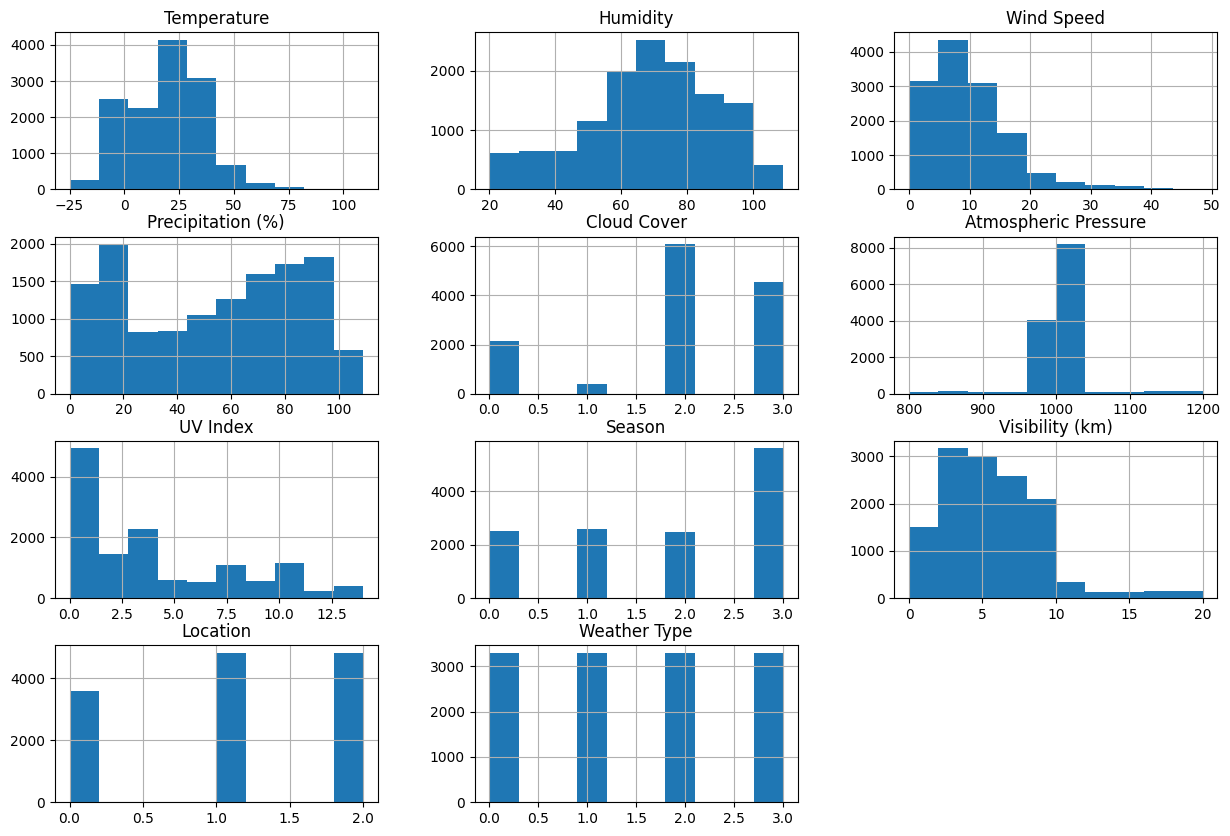

In [7]:
df_encoded.hist(figsize=(15,10))

##Preprocessing

In [8]:
print("Total duplicated rows (excluding first occurrence):", df_encoded.duplicated(keep="first").sum())
print("Total duplicated rows (including all occurrences):", df_encoded.duplicated(keep=False).sum())

Total duplicated rows (excluding first occurrence): 0
Total duplicated rows (including all occurrences): 0


In [9]:
df_encoded.isnull().sum()

,0
Temperature,0
Humidity,0
Wind Speed,0
Precipitation (%),0
Cloud Cover,0
Atmospheric Pressure,0
UV Index,0
Season,0
Visibility (km),0
Location,0


###Box plot

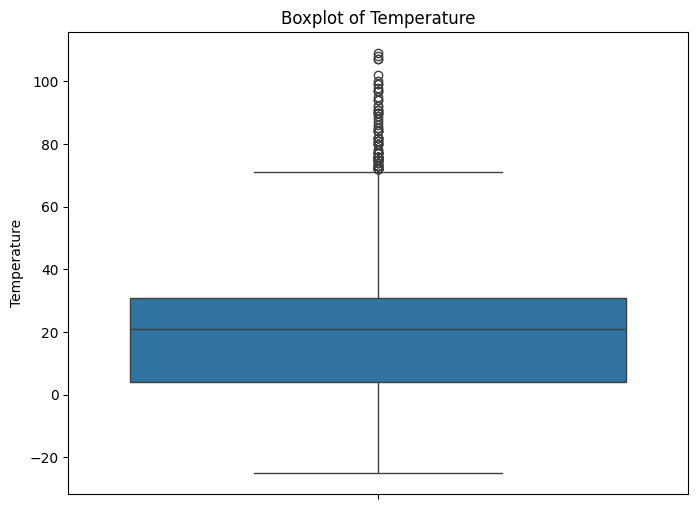

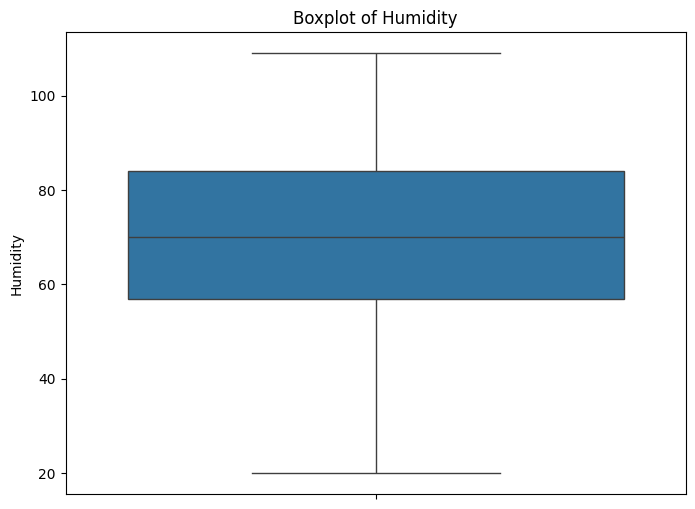

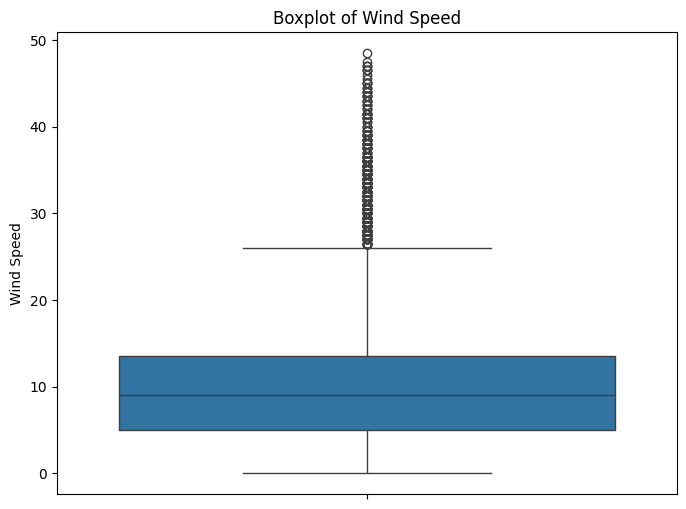

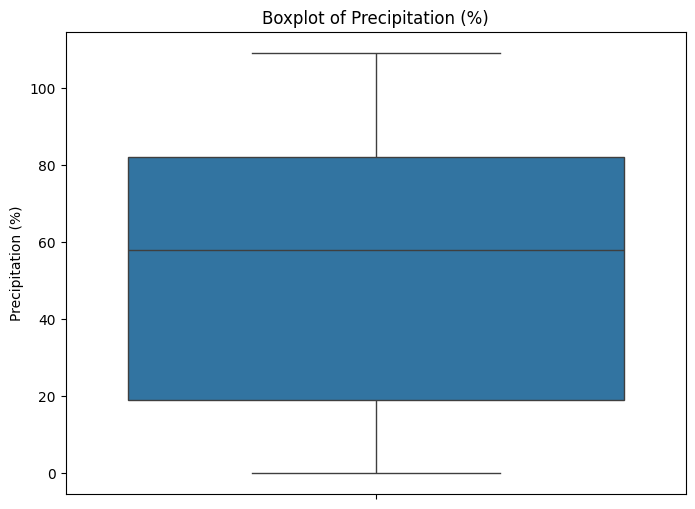

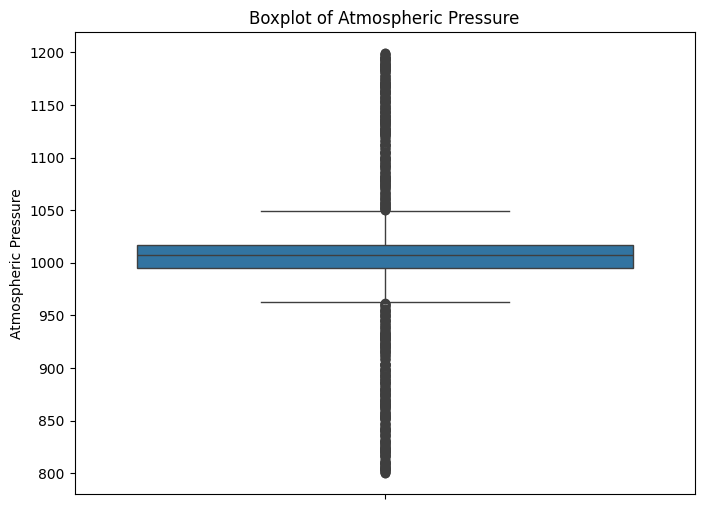

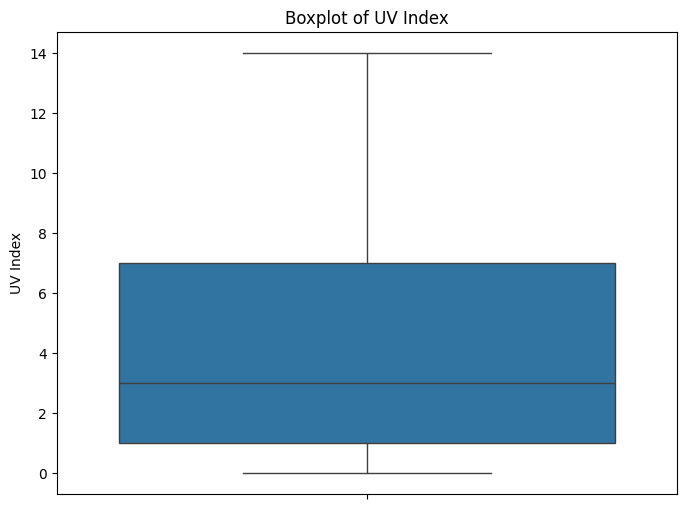

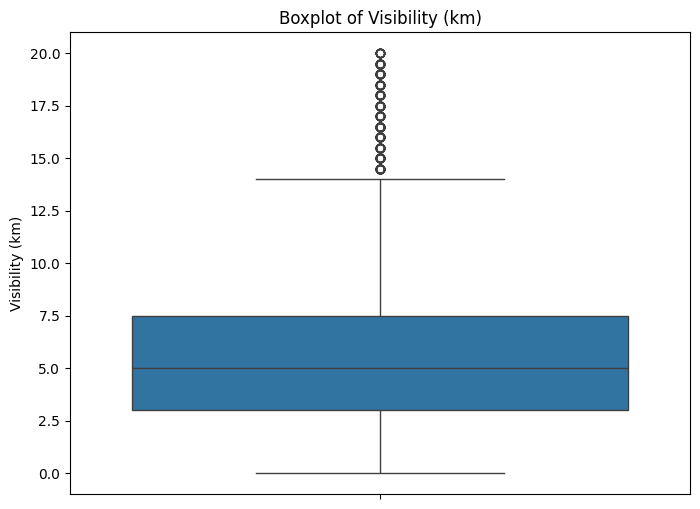

In [10]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    sns.boxplot(y=df_encoded[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)
    plt.show()

###Membersihkan Outlier

In [11]:

print("Numerical columns for outlier detection:", numerical_cols)

Q1 = df_encoded[numerical_cols].quantile(0.25)
Q3 = df_encoded[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_cleaned = df_encoded.copy()
for col in numerical_cols:
    df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound[col]) & (df_cleaned[col] <= upper_bound[col])]

print("\nOriginal number of rows:", len(df_encoded))
print("Number of rows after removing outliers:", len(df_cleaned))

display(df_cleaned.head())

Numerical columns for outlier detection: ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)']

Original number of rows: 13200
Number of rows after removing outliers: 11689


,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14,73,9.5,82,3,1010.82,2,3,3.5,1,1
1,39,96,8.5,71,3,1011.43,7,1,10.0,1,0
2,30,64,7.0,16,0,1018.72,5,1,5.5,2,3
3,38,83,1.5,82,0,1026.25,7,1,1.0,0,3
4,27,74,17.0,66,2,990.67,1,3,2.5,2,1


In [12]:
df_cleaned = df_cleaned[(df_cleaned['Precipitation (%)'] <= 100) & (df_cleaned['Humidity'] <= 100)].copy()

print("Original number of rows in cleaned data:", len(df_cleaned))
print("Number of rows after filtering Precipitation and Humidity:", len(df_cleaned))

Original number of rows in cleaned data: 11169
Number of rows after filtering Precipitation and Humidity: 11169


array([[<Axes: title={'center': 'Temperature'}>,
        <Axes: title={'center': 'Humidity'}>,
        <Axes: title={'center': 'Wind Speed'}>],
       [<Axes: title={'center': 'Precipitation (%)'}>,
        <Axes: title={'center': 'Cloud Cover'}>,
        <Axes: title={'center': 'Atmospheric Pressure'}>],
       [<Axes: title={'center': 'UV Index'}>,
        <Axes: title={'center': 'Season'}>,
        <Axes: title={'center': 'Visibility (km)'}>],
       [<Axes: title={'center': 'Location'}>,
        <Axes: title={'center': 'Weather Type'}>, <Axes: >]], dtype=object)

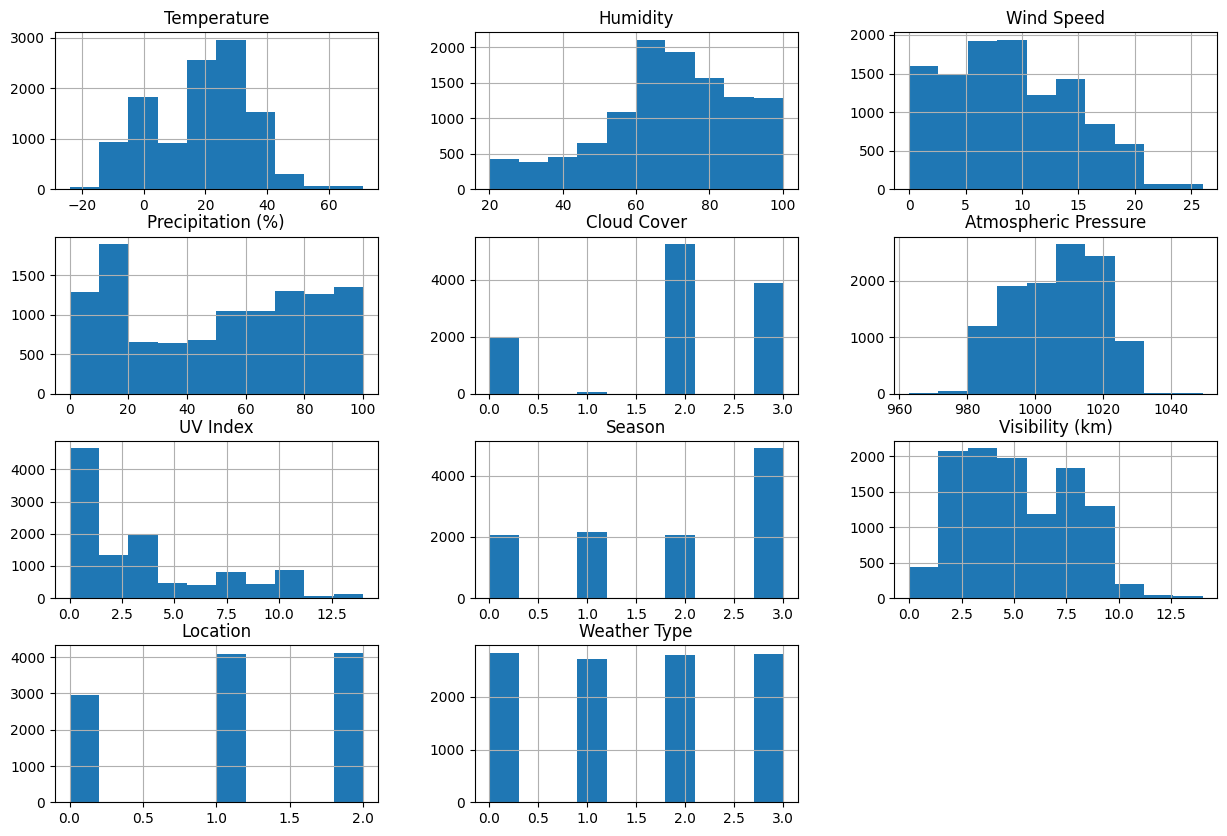

In [13]:
df_cleaned.hist(figsize=(15,10))

##Analisis korelasi

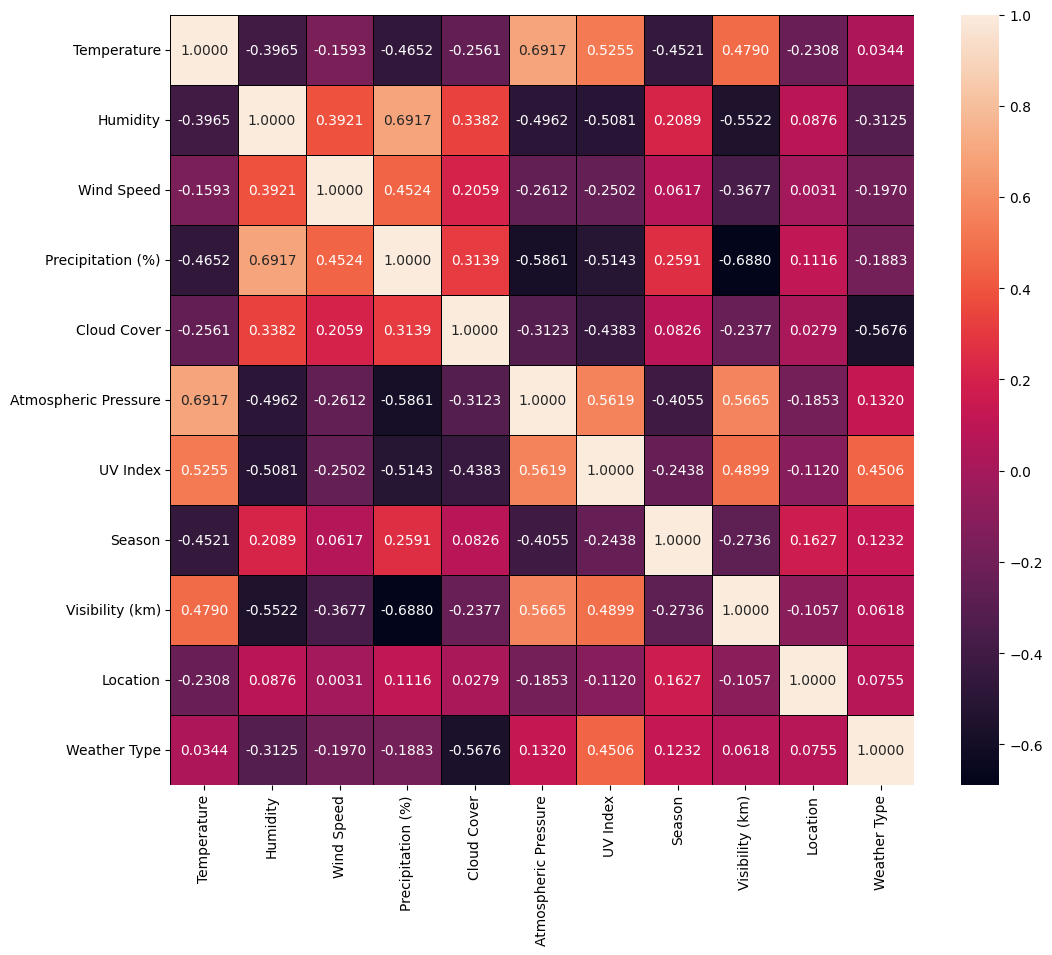

In [14]:
f, ax = plt.subplots(figsize = (12,10))
sns.heatmap(df_cleaned.corr(), annot = True, linewidths=0.5, linecolor = "black", fmt = ".4f", ax = ax)
plt.show()

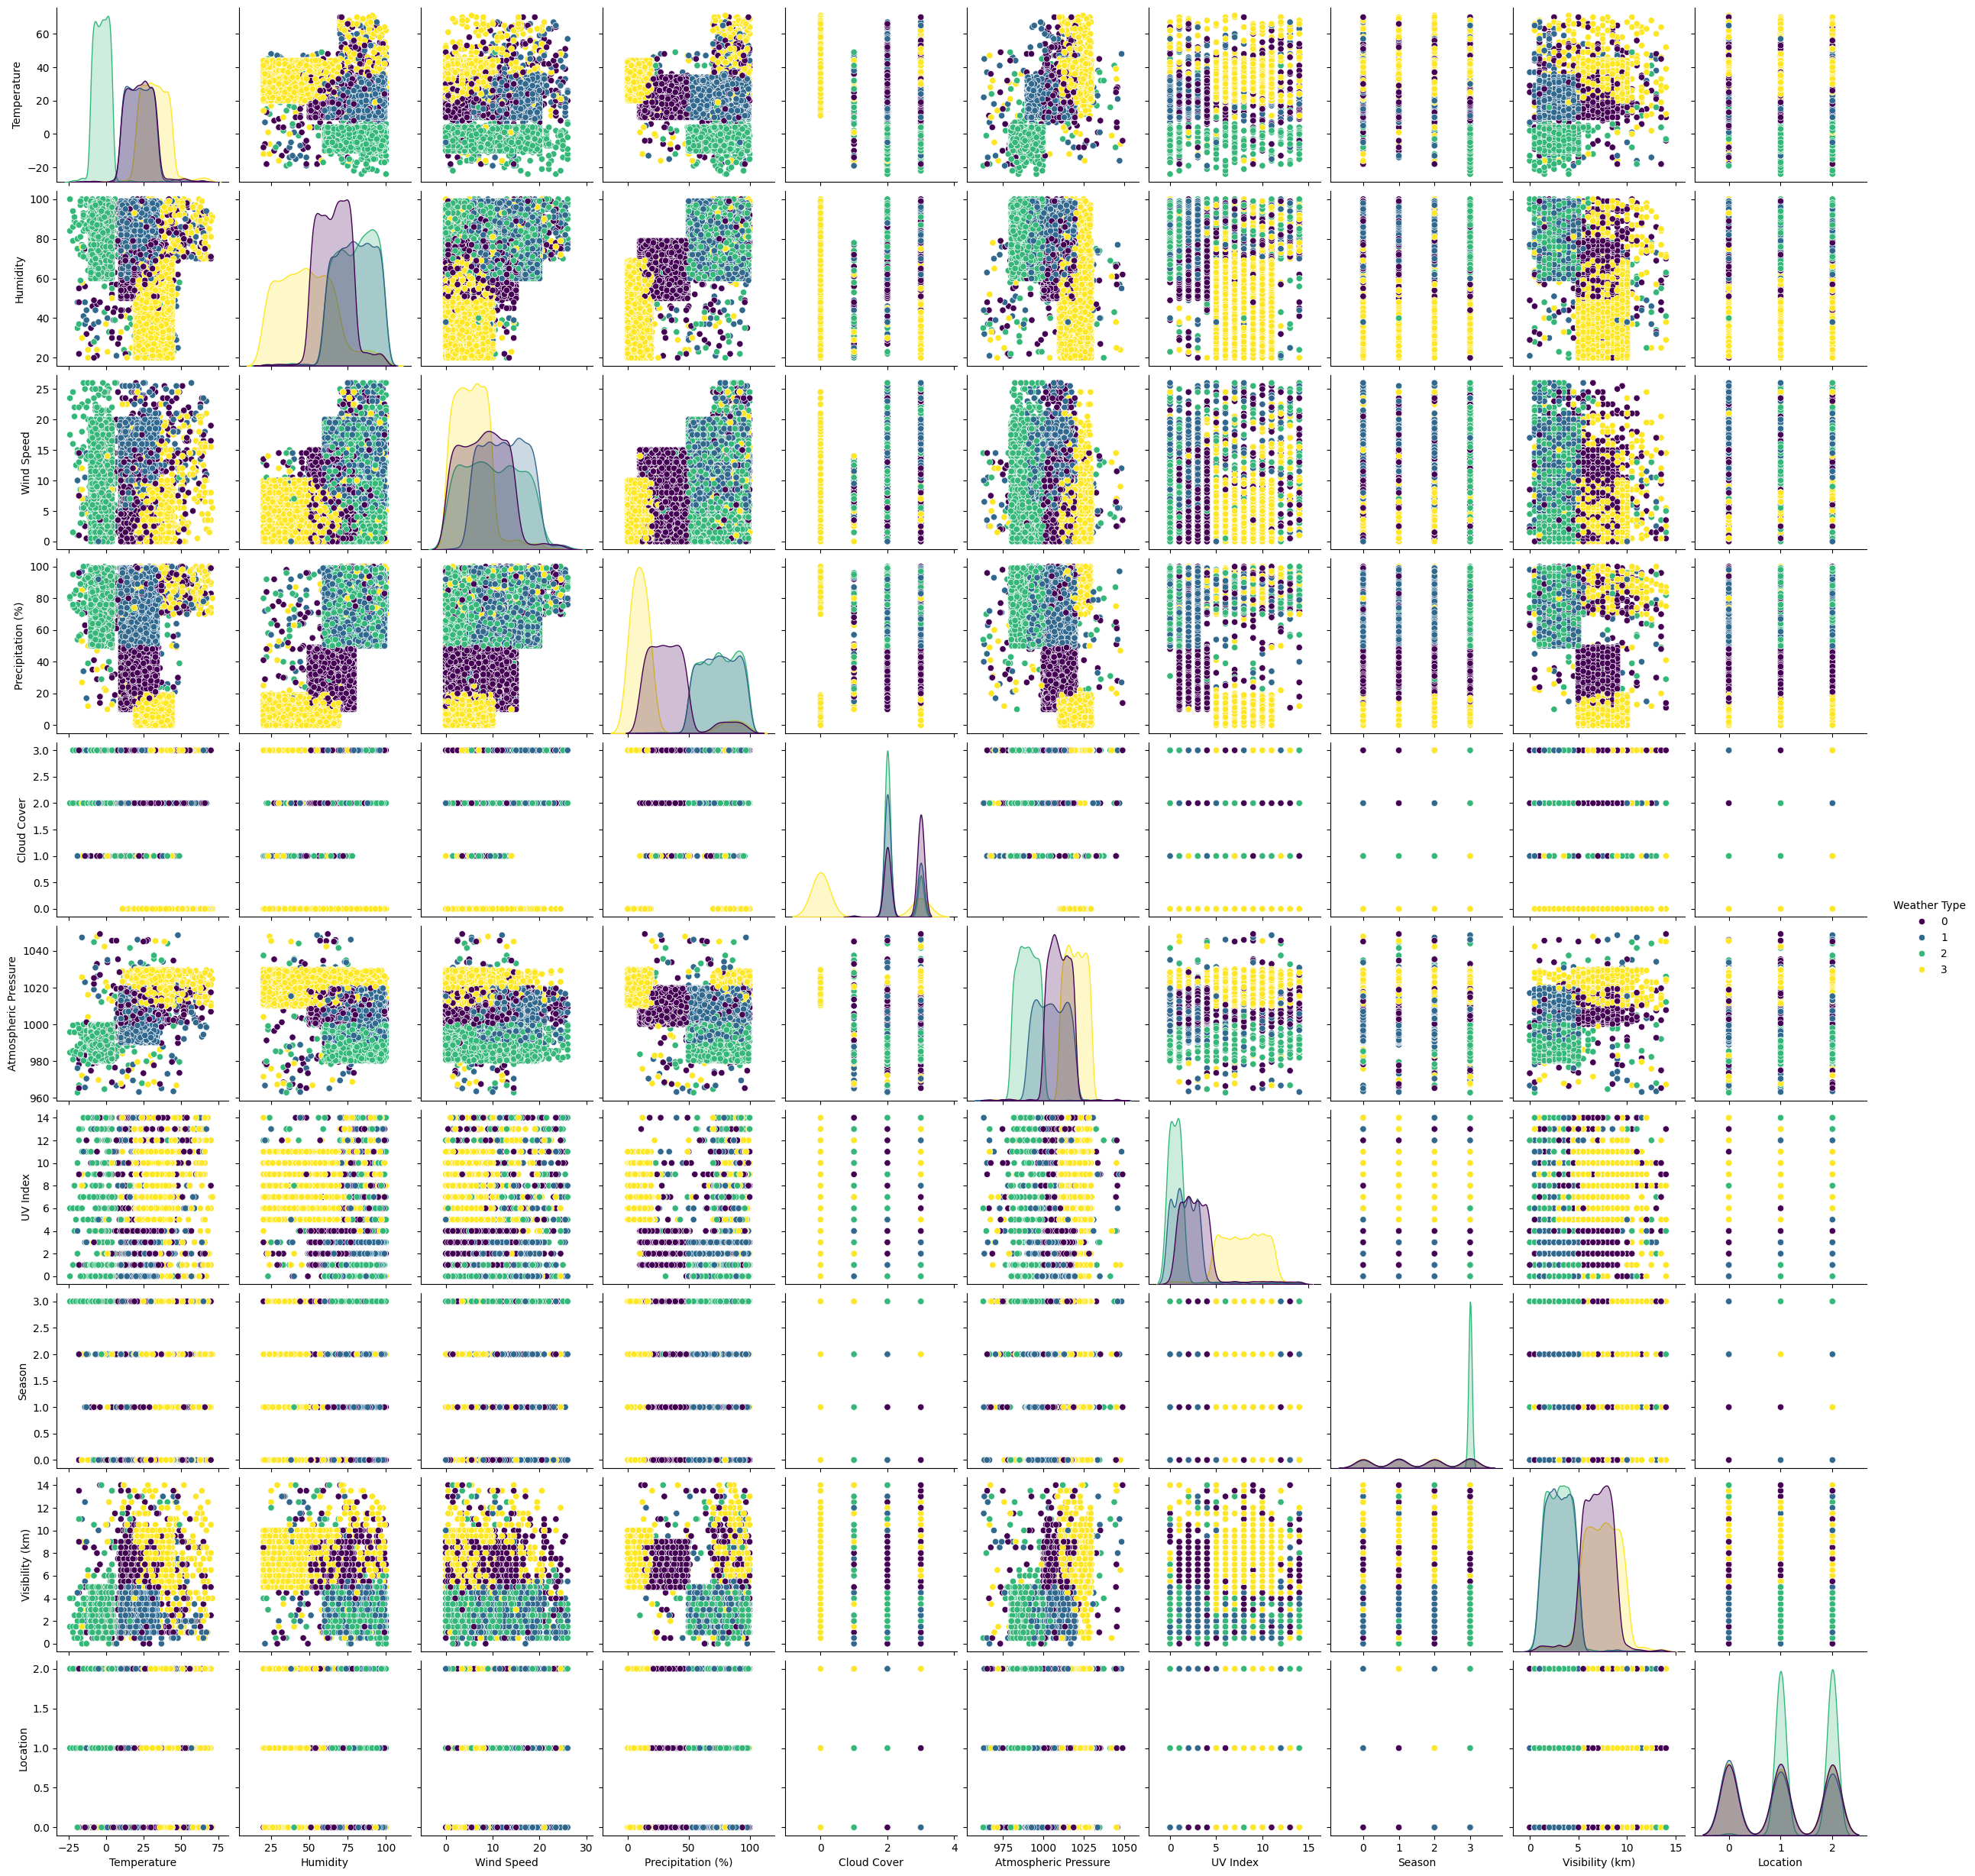

In [15]:
# Visualize pairplot with hue and palette
sns.pairplot(df_cleaned, hue='Weather Type', palette='viridis')
plt.show()

##Seleksi Parameter

##PCA

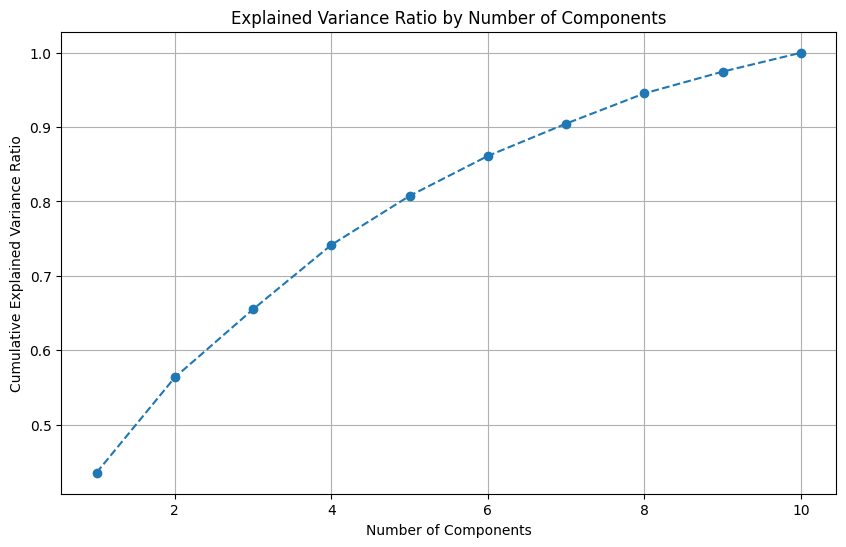

In [16]:
features = df_cleaned.drop('Weather Type', axis=1)

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

pca = PCA()
pca.fit(scaled_features)

explained_variance_ratio = pca.explained_variance_ratio_

cumulative_explained_variance_ratio = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance_ratio) + 1), cumulative_explained_variance_ratio, marker='o', linestyle='--')
plt.title('Explained Variance Ratio by Number of Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.grid(True)
plt.show()

In [27]:
pca = PCA(n_components=0.90)
pca.fit(scaled_features)
pca_data = pca.transform(scaled_features)

columns = ['PCA1', 'PCA2', 'PCA3', 'PCA4', 'PCA5', 'PCA6', 'PCA7']

df_final = pd.DataFrame(pca_data, columns=columns)
df_final

,PCA1,PCA2,PCA3,PCA4,PCA5,PCA6,PCA7
0,1.297895,-0.123102,0.380858,-0.250201,0.533270,0.839731,0.276295
1,-0.860087,-1.429321,0.487310,0.900751,0.354262,1.538117,-0.389896
2,-1.939274,0.605317,-1.434286,0.859933,-0.845631,-0.090548,-0.665676
3,-1.193715,-1.265194,-1.700668,-1.365126,-2.290808,1.834924,0.435133
4,1.895625,0.123852,-1.064862,0.620763,0.856458,-0.087085,-0.103373
...,...,...,...,...,...,...,...
11164,-0.648195,-1.299841,0.449765,-0.697928,0.102995,-0.998313,-0.248826
11165,1.893883,0.021178,-0.918112,0.828868,-0.078054,-0.301024,0.246736
11166,-1.722702,-1.379890,1.147393,-0.243809,-0.837338,-0.076156,-0.944718
11167,2.780468,0.510117,-0.211466,-0.861284,-0.386491,-0.222465,0.236237
